# Evaluación final — Detección de fraude (Caso 1)

Se comparan los cuatro modelos con su validación cruzada en train (paso 9), se fija el umbral sin mirar el test, se evalúa el modelo elegido **una sola vez** en test (paso 10), se analizan sus errores (paso 11) y se presentan las conclusiones (paso 12).

Se importan las librerías, la configuración compartida y se definen los modelos a comparar.

In [1]:
import sys
sys.path.append("..")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             confusion_matrix, precision_score, recall_score, f1_score)
from comun.comun import RES, cargar_test, guardar

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

MODELOS = {"Regresión Logística": "regresion_logistica", "Árbol de Decisión": "arbol_decision",
           "Random Forest": "random_forest", "Gradient Boosting": "gradient_boosting"}
COLORES = {"Regresión Logística": "#0072B2", "Árbol de Decisión": "#E69F00",
           "Random Forest": "#009E73", "Gradient Boosting": "#D55E00"}

def umbral_f1(y, p):
    pr, rc, u = precision_recall_curve(y, p)
    f = 2 * pr * rc / (pr + rc + 1e-12)
    k = f[:-1].argmax()
    return u[k], pr[k], rc[k], f[k]

## 1. Comparación de modelos en validación cruzada (paso 9)

Se cargan las métricas de CV guardadas por cada notebook y se ordenan los modelos por PR-AUC, la métrica principal con clases desbalanceadas.

In [2]:
cv = pd.concat({m: pd.read_csv(RES / f"cv_{f}.csv", index_col="métrica") for m, f in MODELOS.items()}, axis=1)
tabla_cv = pd.DataFrame({m: {"PR-AUC media": cv.loc["pr_auc", (m, "media")], "PR-AUC desv.": cv.loc["pr_auc", (m, "std")],
                             "ROC-AUC media": cv.loc["roc_auc", (m, "media")], "ROC-AUC desv.": cv.loc["roc_auc", (m, "std")]}
                         for m in MODELOS}).T.sort_values("PR-AUC media", ascending=False)
tabla_cv

,PR-AUC media,PR-AUC desv.,ROC-AUC media,ROC-AUC desv.
Gradient Boosting,0.0619,0.0067,0.7062,0.0199
Random Forest,0.0569,0.0098,0.7007,0.0261
Regresión Logística,0.0505,0.0076,0.6806,0.0262
Árbol de Decisión,0.0397,0.0054,0.6718,0.0239


Se calculan, con las predicciones fuera de fold de train, las métricas operativas de cada modelo: su umbral óptimo de F1 y lo que detectaría revisando el 10% de transacciones de mayor riesgo.

In [3]:
oof = {m: pd.read_csv(RES / f"oof_{f}.csv") for m, f in MODELOS.items()}
filas = {}
for m, d in oof.items():
    u, p, r, f = umbral_f1(d["y"], d["proba"])
    top = d["proba"] >= np.quantile(d["proba"], 0.90)
    filas[m] = {"umbral F1": u, "Precision": p, "Recall": r, "F1": f,
                "Recall revisando 10%": d.loc[top, "y"].sum() / d["y"].sum(),
                "Precision revisando 10%": d.loc[top, "y"].mean()}
pd.DataFrame(filas).T.loc[tabla_cv.index]

,umbral F1,Precision,Recall,F1,Recall revisando 10%,Precision revisando 10%
Gradient Boosting,0.3295,0.0841,0.1472,0.1071,0.3177,0.0577
Random Forest,0.1849,0.0777,0.1541,0.1033,0.2806,0.0510
Regresión Logística,0.6489,0.0629,0.2160,0.0974,0.2765,0.0503
Árbol de Decisión,0.3427,0.0787,0.1197,0.0949,0.2545,0.0423


Se compara el Recall de fraude de los cuatro modelos con el mismo volumen de revisión (del 1% al 30% de las transacciones de mayor riesgo), porque el Recall con el umbral propio de cada modelo depende de cuántas alertas genera.

In [ ]:
recall_rev = {}
for m, d in oof.items():
    recall_rev[m] = {f"{q:.0%}": d.loc[d["proba"] >= np.quantile(d["proba"], 1 - q), "y"].sum() / d["y"].sum()
                     for q in (0.01, 0.02, 0.05, 0.10, 0.20, 0.30)}
    recall_rev[m]["% alertas con umbral F1"] = (d["proba"] >= filas[m]["umbral F1"]).mean()
pd.DataFrame(recall_rev).T.loc[tabla_cv.index]

,1%,2%,5%,10%,20%,30%,% alertas con umbral F1
Gradient Boosting,0.0550,0.0963,0.1884,0.3177,0.4622,0.5983,0.0318
Random Forest,0.0564,0.0935,0.1843,0.2806,0.4567,0.5887,0.0360
Regresión Logística,0.0440,0.0839,0.1678,0.2765,0.4360,0.5708,0.0624
Árbol de Decisión,0.0399,0.0990,0.1733,0.2545,0.4264,0.5736,0.0277


Se grafica el PR-AUC medio de cada modelo con su desviación entre folds, frente al nivel de un clasificador aleatorio.

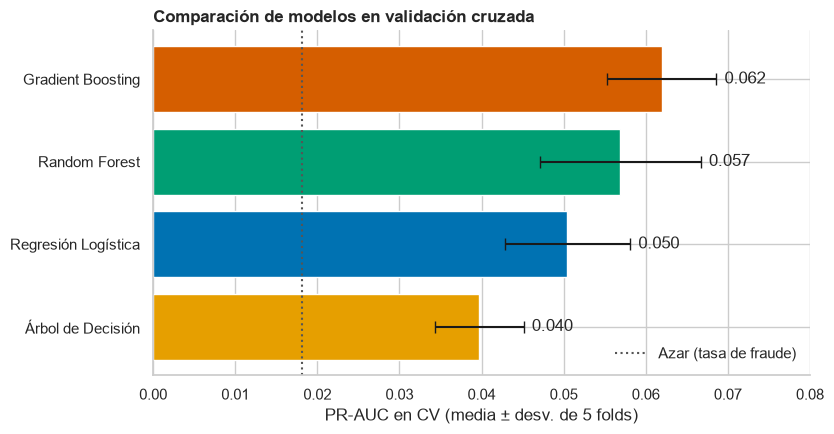

In [4]:
t = tabla_cv.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.barh(t.index, t["PR-AUC media"], xerr=t["PR-AUC desv."], color=[COLORES[m] for m in t.index], capsize=4)
for i, (v, s) in enumerate(zip(t["PR-AUC media"], t["PR-AUC desv."])):
    ax.text(v + s + 0.001, i, f"{v:.3f}", va="center")
ax.axvline(oof["Gradient Boosting"]["y"].mean(), ls=":", color="#555", label="Azar (tasa de fraude)")
ax.set(xlabel="PR-AUC en CV (media ± desv. de 5 folds)", ylabel="", xlim=(0, 0.08))
ax.set_title("Comparación de modelos en validación cruzada", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
sns.despine()
guardar("eval_comparacion_pr_auc")

Se superponen las curvas Precision-Recall fuera de fold de los cuatro modelos.

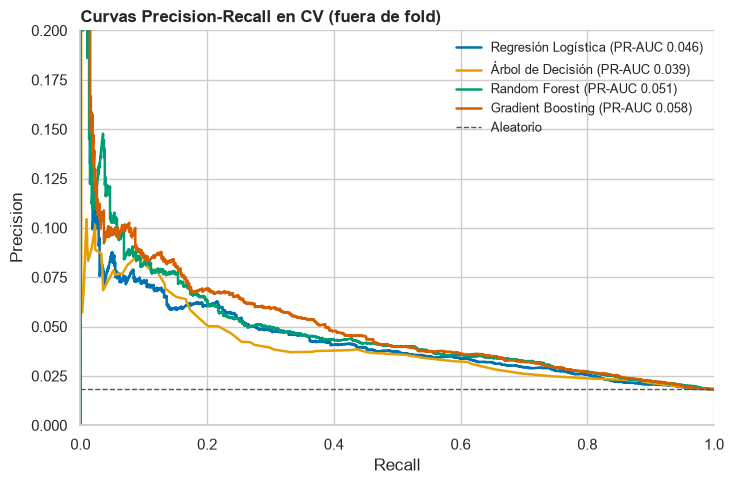

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for m, d in oof.items():
    pr, rc, _ = precision_recall_curve(d["y"], d["proba"])
    ax.plot(rc, pr, color=COLORES[m], lw=1.8, label=f"{m} (PR-AUC {average_precision_score(d['y'], d['proba']):.3f})")
ax.axhline(oof["Gradient Boosting"]["y"].mean(), ls="--", color="#555", lw=1, label="Aleatorio")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title("Curvas Precision-Recall en CV (fuera de fold)", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=9)
sns.despine()
guardar("eval_curvas_pr_cv")

Se elige como modelo final el de mayor PR-AUC en CV, verificando que también tenga el mayor Recall de fraude con el mismo volumen de revisión.

In [6]:
elegido = tabla_cv.index[0]
op = pd.DataFrame(filas).T
print(f"Modelo elegido: {elegido} | PR-AUC CV {tabla_cv.loc[elegido, 'PR-AUC media']:.4f} ± {tabla_cv.loc[elegido, 'PR-AUC desv.']:.4f} | "
      f"ROC-AUC {tabla_cv.loc[elegido, 'ROC-AUC media']:.3f} | Recall revisando 10%: {op.loc[elegido, 'Recall revisando 10%']:.3f} "
      f"(mejor de los 4: {op['Recall revisando 10%'].idxmax()})")

Modelo elegido: Gradient Boosting | PR-AUC CV 0.0619 ± 0.0067 | ROC-AUC 0.706 | Recall revisando 10%: 0.318 (mejor de los 4: Gradient Boosting)


## 2. Umbral de decisión (fijado solo con train)

Se fija el umbral del modelo elegido con sus predicciones fuera de fold de train, maximizando F1, antes de abrir el test.

In [7]:
umbral, p_cv, r_cv, f_cv = umbral_f1(oof[elegido]["y"], oof[elegido]["proba"])
print(f"Umbral fijado con train: {umbral:.3f} → en CV: Precision {p_cv:.3f} | Recall {r_cv:.3f} | F1 {f_cv:.3f}")

Umbral fijado con train: 0.330 → en CV: Precision 0.084 | Recall 0.147 | F1 0.107


## 3. Evaluación única en test (paso 10)

Se carga el modelo final ya entrenado con todo train y se predice el conjunto de test, que no se había usado hasta ahora.

In [8]:
modelo = joblib.load(RES / f"{MODELOS[elegido]}.joblib")
X_test, y_test, ids_test = cargar_test()
proba_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= umbral).astype(int)
print(f"Test: {len(y_test):,} transacciones | {y_test.sum()} fraudes ({y_test.mean()*100:.2f}%) | evaluado una sola vez")

Test: 10,000 transacciones | 182 fraudes (1.82%) | evaluado una sola vez


Se comparan las métricas de CV (train) con las de test para detectar sobreajuste.

In [9]:
cvm = cv[(elegido, "media")]
comparacion = pd.DataFrame({
    "CV (train)": {"PR-AUC": cvm["pr_auc"], "ROC-AUC": cvm["roc_auc"],
                   "Precision (umbral)": p_cv, "Recall (umbral)": r_cv, "F1 (umbral)": f_cv},
    "Test": {"PR-AUC": average_precision_score(y_test, proba_test), "ROC-AUC": roc_auc_score(y_test, proba_test),
             "Precision (umbral)": precision_score(y_test, pred_test, zero_division=0),
             "Recall (umbral)": recall_score(y_test, pred_test), "F1 (umbral)": f1_score(y_test, pred_test)}})
comparacion["diferencia (test − CV)"] = comparacion["Test"] - comparacion["CV (train)"]
comparacion

,CV (train),Test,diferencia (test − CV)
PR-AUC,0.0619,0.0510,-0.0109
ROC-AUC,0.7062,0.7020,-0.0042
Precision (umbral),0.0841,0.0754,-0.0088
Recall (umbral),0.1472,0.1429,-0.0043
F1 (umbral),0.1071,0.0987,-0.0084


Se grafica la curva Precision-Recall del modelo final en test frente a la de CV.

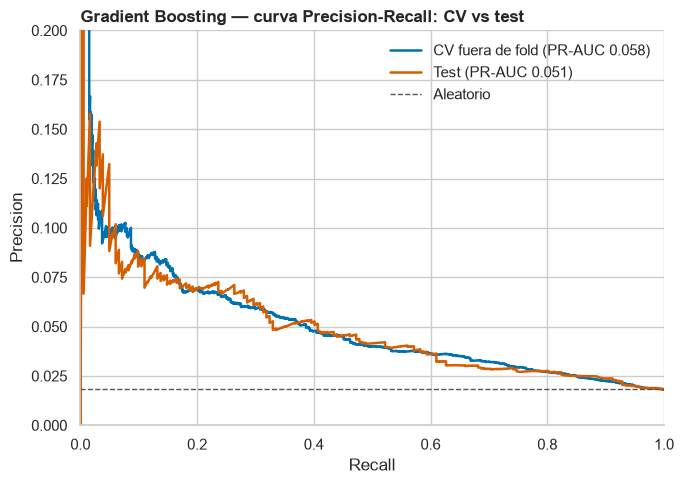

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
pr, rc, _ = precision_recall_curve(oof[elegido]["y"], oof[elegido]["proba"])
ax.plot(rc, pr, color="#0072B2", lw=1.8, label=f"CV fuera de fold (PR-AUC {average_precision_score(oof[elegido]['y'], oof[elegido]['proba']):.3f})")
pr, rc, _ = precision_recall_curve(y_test, proba_test)
ax.plot(rc, pr, color="#D55E00", lw=1.8, label=f"Test (PR-AUC {average_precision_score(y_test, proba_test):.3f})")
ax.axhline(y_test.mean(), ls="--", color="#555", lw=1, label="Aleatorio")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title(f"{elegido} — curva Precision-Recall: CV vs test", loc="left", fontweight="bold")
ax.legend(frameon=False)
sns.despine()
guardar("eval_curva_pr_cv_vs_test")

Se grafica la matriz de confusión del modelo final en test con el umbral fijado en train.

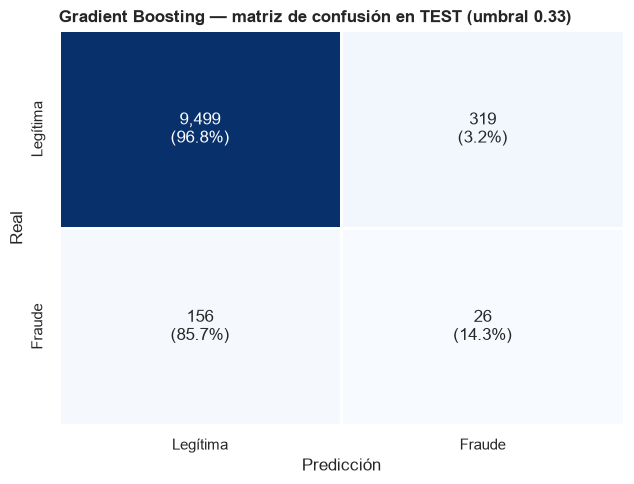

In [11]:
cm = confusion_matrix(y_test, pred_test)
etiquetas = np.array([[f"{v:,}\n({v / fila.sum() * 100:.1f}%)" for v in fila] for fila in cm])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Real")
ax.set_title(f"{elegido} — matriz de confusión en TEST (umbral {umbral:.2f})", loc="left", fontweight="bold")
guardar("eval_matriz_confusion_test")

Se presenta la matriz de confusión de test en formato de tabla.

In [12]:
pd.DataFrame(cm, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,9499,319
Fraude,156,26


Se calcula cuántos fraudes de test se detectarían si el equipo antifraude revisara solo el porcentaje de transacciones de mayor riesgo.

In [13]:
yt = y_test.values
filas_t = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(proba_test, 1 - pct / 100)
    alerta = proba_test >= u
    tp_ = (alerta & (yt == 1)).sum()
    filas_t.append({"% revisado": pct, "alertas": alerta.sum(), "fraudes detectados": tp_,
                    "recall": tp_ / yt.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas_t).set_index("% revisado")

,alertas,fraudes detectados,recall,precision
% revisado,,,,
1,101,9,0.0495,0.0891
2,200,17,0.0934,0.0850
5,500,35,0.1923,0.0700
10,1003,58,0.3187,0.0578
20,2000,87,0.4780,0.0435
30,3000,108,0.5934,0.0360


## 4. Análisis de errores (paso 11)

Se clasifica cada transacción de test como verdadero positivo, falso positivo, falso negativo o verdadero negativo.

In [14]:
err = X_test.assign(transaction_id=ids_test.values, real=y_test.values, proba=proba_test, pred=pred_test)
err["tipo"] = np.select([(err.real == 1) & (err.pred == 1), (err.real == 0) & (err.pred == 1), (err.real == 1) & (err.pred == 0)],
                        ["VP (fraude detectado)", "FP (falsa alarma)", "FN (fraude no detectado)"], "VN (legítima correcta)")
err["tipo"].value_counts().to_frame("transacciones")

,transacciones
tipo,
VN (legítima correcta),9499
FP (falsa alarma),319
FN (fraude no detectado),156
VP (fraude detectado),26


Se compara el perfil de cada tipo de resultado en las variables más influyentes para entender por qué el modelo acierta o se equivoca.

In [15]:
perfil = err.groupby("tipo").agg(
    n=("real", "size"), probabilidad_media=("proba", "mean"),
    monto_mediano=("amount_usd", "median"), gasto_vs_habitual_mediano=("amount_vs_avg", "median"),
    pct_fuera_EC=("country", lambda s: (s != "EC").mean() * 100),
    pct_tarjeta_presente=("card_present", lambda s: s.mean() * 100),
    pct_dispositivo_nuevo=("new_device", lambda s: s.mean() * 100),
    pct_madrugada=("hour", lambda s: ((s >= 23) | (s <= 4)).mean() * 100),
    pct_viajes=("merchant_category", lambda s: (s == "viajes").mean() * 100))
perfil

,n,probabilidad_media,monto_mediano,gasto_vs_habitual_mediano,pct_fuera_EC,pct_tarjeta_presente,pct_dispositivo_nuevo,pct_madrugada,pct_viajes
tipo,,,,,,,,,
FN (fraude no detectado),156,0.1803,66.4000,1.3735,32.0513,32.6923,11.5385,26.9231,7.0513
FP (falsa alarma),319,0.3935,271.2800,8.4340,69.9060,18.4953,30.0940,50.1567,15.0470
VN (legítima correcta),9499,0.1387,53.1800,1.2100,18.9915,50.3106,9.1589,23.8130,5.5901
VP (fraude detectado),26,0.4083,242.0800,7.3860,80.7692,19.2308,11.5385,61.5385,30.7692


Se listan los 10 fraudes no detectados con menor probabilidad asignada, los más difíciles para el modelo.

In [16]:
err[err["tipo"].str.startswith("FN")].sort_values("proba").head(10)[["transaction_id", "proba", "amount_usd", "amount_vs_avg", "country", "channel", "card_present", "new_device", "hour", "merchant_category"]]

,transaction_id,proba,amount_usd,amount_vs_avg,country,channel,card_present,new_device,hour,merchant_category
8609,TX20260907030357,0.0607,24.8700,1.4200,EC,ATM,1,0,20,retail
1434,TX20260907049212,0.0653,15.8700,0.1260,EC,POS,1,0,12,transporte
3900,TX20260907000412,0.0662,9.2700,0.2430,EC,ATM,1,0,10,entretenimiento
2405,TX20260907044068,0.0662,7.9300,0.0930,EC,POS,1,0,21,alimentos
4941,TX20260907002735,0.0662,11.9800,0.1180,EC,POS,1,0,5,alimentos
5236,TX20260907014283,0.0662,2.9100,0.0220,EC,POS,1,0,9,alimentos
9252,TX20260907000739,0.0662,83.2000,0.8830,EC,POS,1,0,7,retail
775,TX20260907016390,0.0665,72.6000,1.3750,EC,POS,1,0,12,retail
7499,TX20260907019379,0.0672,40.7600,0.6610,EC,POS,1,0,17,transporte
2282,TX20260907013720,0.0674,61.8600,2.0120,EC,POS,1,0,16,retail


Se listan las 10 falsas alarmas con mayor probabilidad asignada, las transacciones legítimas que más se parecen a un fraude.

In [17]:
err[err["tipo"].str.startswith("FP")].sort_values("proba", ascending=False).head(10)[["transaction_id", "proba", "amount_usd", "amount_vs_avg", "country", "channel", "card_present", "new_device", "hour", "merchant_category"]]

,transaction_id,proba,amount_usd,amount_vs_avg,country,channel,card_present,new_device,hour,merchant_category
841,TX20260907004409,0.6433,983.5300,50.2310,CO,WEB,0,1,5,retail
9526,TX20260907002836,0.6275,"1,009.7700",36.1540,OTRO,WEB,0,0,1,retail
4229,TX20260907040786,0.5824,966.6000,8.2930,EC,WEB,0,0,1,viajes
2613,TX20260907010616,0.5757,253.1100,8.0000,CO,APP,0,1,0,tecnologia
9477,TX20260907022686,0.5474,196.0100,6.8180,CO,WEB,0,0,0,entretenimiento
5292,TX20260907012165,0.5370,"1,034.7900",131.8200,CO,WEB,0,0,11,entretenimiento
8880,TX20260907002277,0.5369,"1,146.6300",43.6650,MX,WEB,0,0,15,retail
4274,TX20260907027053,0.5354,"1,698.2800",59.1740,PE,APP,0,0,16,otros
8011,TX20260907034105,0.5343,783.6300,16.0980,EC,WEB,0,0,4,viajes
9773,TX20260907035740,0.5343,"1,182.9200",29.8340,OTRO,WEB,0,0,12,entretenimiento


Se cuantifica el impacto operativo en test: monto de fraude detectado y no detectado, y volumen de alertas que tendría que revisar el equipo antifraude.

In [18]:
fraude = err[err["real"] == 1]
monto_total = fraude["amount_usd"].sum()
monto_det = fraude.loc[fraude["pred"] == 1, "amount_usd"].sum()
print(f"Monto de fraude en test: ${monto_total:,.0f} | detectado: ${monto_det:,.0f} ({monto_det/monto_total*100:.1f}%) | "
      f"no detectado: ${monto_total - monto_det:,.0f} ({(1 - monto_det/monto_total)*100:.1f}%) | "
      f"alertas a revisar: {err['pred'].sum():,} ({err['pred'].mean()*100:.1f}% de las transacciones), "
      f"de ellas {(err['tipo'] == 'FP (falsa alarma)').sum():,} falsas")

Monto de fraude en test: $29,642 | detectado: $11,523 (38.9%) | no detectado: $18,119 (61.1%) | alertas a revisar: 345 (3.5% de las transacciones), de ellas 319 falsas


## 5. Conclusiones (paso 12)

**Selección del modelo (paso 9).** Se elige **Gradient Boosting** (tocones de profundidad 1, tasa 0.03, 400 iteraciones, peso de fraude ×10) por tener el mayor PR-AUC en CV (0.062 ± 0.007) y el mayor Recall al revisar el 10% de mayor riesgo (31.8%). Su ventaja sobre Random Forest (0.057) y la Regresión Logística (0.051) es pequeña frente a la variación entre folds, por lo que los tres primeros son competitivos; el Árbol de Decisión queda claramente atrás (0.040).

**Evaluación en test (paso 10).** Con el umbral fijado en train (0.33), el modelo evaluado una sola vez en test obtiene PR-AUC 0.051, ROC-AUC 0.702, Precision 0.075, Recall 0.143 y F1 0.099. El ROC-AUC, la precisión y el recall son prácticamente iguales a los de CV, y revisando el 10% de mayor riesgo detecta el 31.9% de los fraudes (31.8% en CV): **no hay sobreajuste relevante**. La caída del PR-AUC (−0.011) es de unas 1.6 desviaciones entre folds y se explica por la variabilidad de una muestra con solo 182 fraudes y por el leve optimismo de haber elegido el mejor de muchos modelos en CV.

**Análisis de errores (paso 11).** En test el modelo genera 345 alertas (3.5% de las transacciones): 26 fraudes detectados y 319 falsas alarmas, mientras 156 fraudes pasan sin detectar.
- Los **falsos negativos** tienen perfil de transacción legítima (monto mediano $66, gasto 1.4× el habitual, 68% en Ecuador, un tercio con tarjeta presente); los más difíciles son compras pequeñas en Ecuador con tarjeta física en POS/ATM. No hay señal de riesgo que el modelo pueda usar.
- Las **falsas alarmas** tienen perfil de fraude (monto mediano $271, gasto 8.4× el habitual, 70% fuera de Ecuador, 82% sin tarjeta, la mitad de madrugada); son legítimas que se parecen a fraudes.
- **Impacto operativo:** un falso negativo es una pérdida directa para el cliente y la entidad; un falso positivo cuesta tiempo de revisión y molestias al cliente (bloqueos). El modelo detecta solo el 14% de los fraudes en número, pero el **39% del monto defraudado** ($11,523 de $29,642), porque atrapa sobre todo los fraudes grandes.

**Variables más influyentes.** En todos los modelos coinciden: país distinto de Ecuador, tarjeta no presente y canal digital (WEB/APP), gasto muy por encima del habitual (`amount_vs_avg`) y monto, dispositivo nuevo, madrugada (23:00–04:00) y la categoría viajes. `device_type`, `day_of_week`, `account_age_days` e `ip_risk_score` casi no aportan.

**Limitaciones.**
- Los datos son **sintéticos** (fecha única en `transaction_id` frente a 7 días de la semana, hora y día uniformes, montos log-normales exactos); la señal es real pero débil y **aditiva** (los tocones, sin interacciones, son el mejor modelo).
- Todos los modelos chocan con el mismo techo (PR-AUC ≈ 0.05–0.06, unas 3 veces el azar).
- Pocos fraudes (727 en train, 182 en test) y 6,558 clientes compartidos entre train y test; no hay fechas para validar en el tiempo.

**Acciones necesarias antes de un despliegue real.**
1. **No desplegar** este modelo como sistema de bloqueo automático: su precisión (≈ 8%) generaría unas 12 falsas alarmas por cada fraude detectado.
2. Como mucho, usarlo como **apoyo para priorizar** la revisión manual (el 1% de mayor riesgo concentra unas 5 veces más fraude que el azar).
3. Obtener **datos reales y más ricos**: historial y velocidad de transacciones del cliente, identificador y tasa de fraude del comercio, huella de dispositivo e IP, cambios recientes en la cuenta y fraudes confirmados (contracargos).
4. Validar **en el tiempo** (entrenar con meses pasados y probar con meses futuros) y **separando por cliente** para evitar estimaciones optimistas.
5. Definir el umbral con el negocio según el **costo real** de cada falso negativo y falso positivo y la capacidad del equipo de revisión.
6. Monitorear el rendimiento y el cambio en los datos tras el despliegue, y reentrenar periódicamente.